---
title: "Vector Calculus for Fields"
short_title: "E-M1 Vector Calculus for Fields"
numbering:
  heading_2: true
  equation: true
---

# Vector Calculus for Fields

:::{tip} Where this sits in the plan
Math for **electrostatics, potentials, dielectrics, magnetostatics and Maxwell's equations** (E&M topics 1, 2, 5, 6, 7). Partial derivatives and the gradient are in mechanics M3; multiple integrals, Jacobians and the 1D delta function are in M2.

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Vector calculus (div, curl, theorems) | 16 | 6 | 9 | 3 |
| Spherical and cylindrical coordinates | 15 | 5, 6 | – | 3 |
| Dirac delta function (3D) | – | 7, 8 | 4 | 1 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns. `sympy.vector` handles curvilinear coordinates, so you can check every formula in the tables.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## Three Derivatives of a Field

With the operator $\nabla = \hat{x}\,\partial_x + \hat{y}\,\partial_y + \hat{z}\,\partial_z$, there are three first derivatives:

| Operation | Acts on | Gives | Measures |
|---|---|---|---|
| gradient $\nabla f$ | scalar | vector | direction and rate of fastest increase |
| divergence $\nabla\cdot\vec{A}$ | vector | scalar | net outflow per unit volume (sources) |
| curl $\nabla\times\vec{A}$ | vector | vector | circulation per unit area (swirl) |

The precise meanings come from the limits:

$$
\nabla\cdot\vec{A} = \lim_{V\to0}\frac{1}{V}\oint_{\partial V}\vec{A}\cdot d\vec{a}, \qquad
\hat{n}\cdot(\nabla\times\vec{A}) = \lim_{S\to0}\frac{1}{S}\oint_{\partial S}\vec{A}\cdot d\vec{l} .
$$

These limit definitions do not mention coordinates, which is why the curvilinear formulas below, ugly as they look, describe the same things.

### The fundamental theorems

Each derivative has a theorem relating its integral over a region to the field on the boundary:

$$
\int_a^b\nabla f\cdot d\vec{l} = f(b) - f(a), \qquad
\int_V\nabla\cdot\vec{A}\,d\tau = \oint_{\partial V}\vec{A}\cdot d\vec{a}, \qquad
\int_S(\nabla\times\vec{A})\cdot d\vec{a} = \oint_{\partial S}\vec{A}\cdot d\vec{l} .
$$ (eq-fundamental-theorems)

E&M uses them constantly to switch between the **integral** form of a law (good for symmetric problems) and the **differential** form (good for everything else).

### Second derivatives and identities

Two combinations always vanish (for smooth fields):

$$
\nabla\times(\nabla f) = \vec{0}, \qquad \nabla\cdot(\nabla\times\vec{A}) = 0 ,
$$

and two others are important:

$$
\nabla\cdot(\nabla f) = \nabla^2f \ \ (\text{the Laplacian}), \qquad
\nabla\times(\nabla\times\vec{A}) = \nabla(\nabla\cdot\vec{A}) - \nabla^2\vec{A} .
$$ (eq-curl-curl)

The product rules worth having at hand:

$$
\begin{aligned}
\nabla\cdot(f\vec{A}) &= f\,\nabla\cdot\vec{A} + \vec{A}\cdot\nabla f, \\
\nabla\times(f\vec{A}) &= f\,\nabla\times\vec{A} - \vec{A}\times\nabla f, \\
\nabla\cdot(\vec{A}\times\vec{B}) &= \vec{B}\cdot(\nabla\times\vec{A}) - \vec{A}\cdot(\nabla\times\vec{B}) .
\end{aligned}
$$

The last one gives Poynting's theorem for energy flow in electromagnetic fields.

In [2]:
# Check the identities on arbitrary symbolic fields
from sympy.vector import CoordSys3D, gradient, divergence, curl
N = CoordSys3D("N")
f = sp.Function("f")(N.x, N.y, N.z)
A = sum((sp.Function(n)(N.x, N.y, N.z) * e for n, e in zip("PQR", (N.i, N.j, N.k))), sp.vector.Vector.zero)
B = sum((sp.Function(n)(N.x, N.y, N.z) * e for n, e in zip("UVW", (N.i, N.j, N.k))), sp.vector.Vector.zero)
display(Math(r"\nabla\times\nabla f = " + sp.latex(sp.simplify(curl(gradient(f)).to_matrix(N).T))))
display(Math(r"\nabla\cdot(\nabla\times\vec{A}) = " + sp.latex(sp.simplify(divergence(curl(A))))))
lhs = divergence(A.cross(B))
rhs = B.dot(curl(A)) - A.dot(curl(B))
display(Math(r"\nabla\cdot(\vec{A}\times\vec{B}) - \left[\vec{B}\cdot(\nabla\times\vec{A}) - \vec{A}\cdot(\nabla\times\vec{B})\right] = " + sp.latex(sp.simplify(lhs - rhs))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exercises

1. Compute $\nabla\cdot\vec{r}$ and $\nabla\times\vec{r}$ for $\vec{r} = \langle x, y, z\rangle$.
2. Show that $\nabla(1/r) = -\hat{r}/r^2$, where $r = |\vec{r}|$.
3. Use {eq}`eq-fundamental-theorems` to show that $\oint\nabla f\cdot d\vec{l} = 0$ around any closed loop, and connect it to $\nabla\times\nabla f = \vec{0}$.

:::{dropdown} Hints
1. Differentiate component by component.
2. $\partial_x(x^2 + y^2 + z^2)^{-1/2} = -x/r^3$.
3. Use the gradient theorem with $a = b$, or Stokes' theorem with the curl.
:::

:::{dropdown} Answers
1. $\nabla\cdot\vec{r} = 3$ and $\nabla\times\vec{r} = \vec{0}$.
2. $\nabla(1/r) = -\langle x, y, z\rangle/r^3 = -\hat{r}/r^2$.
3. The gradient theorem gives $f(a) - f(a) = 0$; Stokes gives $\int(\nabla\times\nabla f)\cdot d\vec{a} = 0$ for every surface, consistent with the curl vanishing.
:::

## Curvilinear Coordinates

Most E&M problems have spherical or cylindrical symmetry. With scale factors $(h_1, h_2, h_3)$, every formula follows the same pattern (mechanics M2 introduced the scale factors). The results:

**Cylindrical** $(s, \phi, z)$:

$$
\begin{aligned}
\nabla f &= \partial_sf\,\hat{s} + \frac1s\partial_\phi f\,\hat{\phi} + \partial_zf\,\hat{z}, \qquad
\nabla\cdot\vec{A} = \frac1s\partial_s(sA_s) + \frac1s\partial_\phi A_\phi + \partial_zA_z, \\
\nabla^2f &= \frac1s\partial_s\left(s\,\partial_sf\right) + \frac1{s^2}\partial_\phi^2f + \partial_z^2f .
\end{aligned}
$$

**Spherical** $(r, \theta, \phi)$:

$$
\begin{aligned}
\nabla f &= \partial_rf\,\hat{r} + \frac1r\partial_\theta f\,\hat{\theta} + \frac{1}{r\sin\theta}\partial_\phi f\,\hat{\phi}, \\
\nabla\cdot\vec{A} &= \frac{1}{r^2}\partial_r\left(r^2A_r\right) + \frac{1}{r\sin\theta}\partial_\theta\left(\sin\theta\,A_\theta\right) + \frac{1}{r\sin\theta}\partial_\phi A_\phi, \\
\nabla^2f &= \frac{1}{r^2}\partial_r\left(r^2\partial_rf\right) + \frac{1}{r^2\sin\theta}\partial_\theta\left(\sin\theta\,\partial_\theta f\right) + \frac{1}{r^2\sin^2\theta}\partial_\phi^2f .
\end{aligned}
$$ (eq-spherical-ops)

The curls are longer; the code below prints them. The factors like $r^2$ inside $\partial_r(r^2A_r)$ are the area factors: flux through a sphere scales with its area $4\pi r^2$.

In [3]:
S = CoordSys3D("S", transformation="spherical", variable_names=("r", "theta", "phi"))
Ar, At, Ap = [sp.Function(n)(S.r, S.theta, S.phi) for n in ("A_r", "A_theta", "A_phi")]
Avec = Ar * S.i + At * S.j + Ap * S.k
plain = {S.r: sp.Symbol("r"), S.theta: sp.Symbol("theta"), S.phi: sp.Symbol("phi")}   # print r, theta, phi instead of S.r, ...
display(Math(r"\nabla\cdot\vec{A} = " + sp.latex(sp.simplify(divergence(Avec)).subs(plain))))
for name, comp in zip(("r", r"\theta", r"\phi"), curl(Avec).to_matrix(S)):
    display(Math(r"(\nabla\times\vec{A})_" + name + " = " + sp.latex(sp.simplify(comp).subs(plain))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exercises

1. Use {eq}`eq-spherical-ops` to compute $\nabla\cdot(r^n\hat{r})$. For which $n$ is it zero away from the origin?
2. Compute $\nabla^2(1/r)$ for $r\neq0$.
3. In cylindrical coordinates, compute $\nabla\times(\hat{\phi}/s)$ for $s\ne0$. (This is the magnetic field shape around a straight wire.)

:::{dropdown} Hints
1. Only the first term of the divergence survives.
2. Only the radial term of the Laplacian survives.
3. Only $A_\phi = 1/s$ is nonzero; the $z$-component of curl is $\frac1s[\partial_s(sA_\phi) - \partial_\phi A_s]$.
:::

:::{dropdown} Answers
1. $\frac{1}{r^2}\partial_r(r^{n+2}) = (n+2)r^{n-1}$, zero for $n = -2$: the inverse-square field.
2. $\frac{1}{r^2}\partial_r\left(r^2\cdot(-1/r^2)\right) = 0$.
3. $\frac1s\partial_s(1) = 0$: curl-free away from the axis, even though it circulates. All the curl is on the axis, as a delta function.
:::

## The Divergence of $\hat{r}/r^2$

The inverse-square field $\vec{v} = \hat{r}/r^2$ (the shape of the field of a point charge) has zero divergence everywhere except the origin, by the exercise above. Yet its flux through a sphere of any radius is

$$
\oint\frac{\hat{r}}{r^2}\cdot\hat{r}\,r^2\sin\theta\,d\theta\,d\phi = 4\pi \neq 0 .
$$

The divergence theorem says the volume integral of the divergence must also be $4\pi$. All of it is concentrated at the single point $r = 0$. The resolution is the 3D delta function (mechanics M2 covered the 1D version):

$$
\nabla\cdot\left(\frac{\hat{r}}{r^2}\right) = 4\pi\,\delta^3(\vec{r}), \qquad
\nabla^2\frac1r = -4\pi\,\delta^3(\vec{r}) ,
$$ (eq-div-rhat)

where $\delta^3(\vec{r}) = \delta(x)\delta(y)\delta(z)$ and $\int_V\delta^3(\vec{r})\,d\tau = 1$ if $V$ contains the origin. Shifting the origin, with the **separation vector** $\vec{\mathscr{r}} = \vec{r} - \vec{r}'$ from source point to field point,

$$
\nabla^2\frac{1}{|\vec{r} - \vec{r}'|} = -4\pi\,\delta^3(\vec{r} - \vec{r}') .
$$

This single equation is Coulomb's law turned into Gauss's law, and it is the Green's function of the Laplacian.

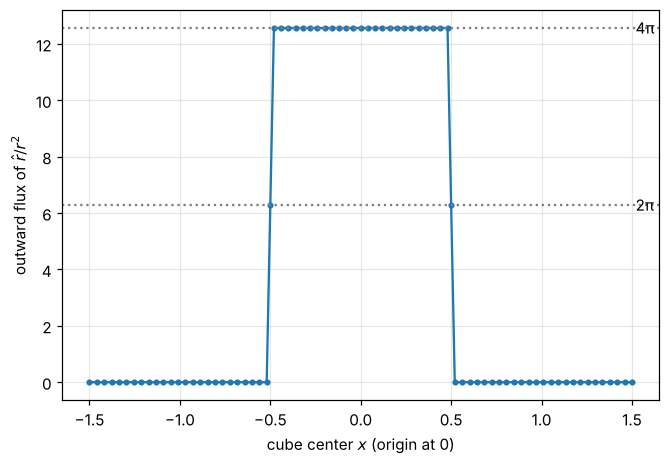

In [4]:
#| label: fig-flux-step
#| caption: Flux of r̂/r² out of a unit cube, computed numerically as the cube slides along x. It is 4π whenever the origin is inside, 0 when outside, and 2π when the origin sits on a face. All of the divergence lives at one point.
def cube_flux(cx, n=160):   # even n keeps grid points off the origin
    # flux through the 6 faces of a unit cube centered at (cx, 0, 0), midpoint rule
    u = (np.arange(n) + 0.5) / n - 0.5
    U, V = np.meshgrid(u, u)
    total = 0.0
    for axis in range(3):
        for sgn in (+1, -1):
            pts = [None, None, None]
            pts[axis] = np.full_like(U, sgn * 0.5)
            others = [k for k in range(3) if k != axis]
            pts[others[0]], pts[others[1]] = U, V
            x, y, z = pts[0] + cx, pts[1], pts[2]
            r3 = (x**2 + y**2 + z**2)**1.5
            comp = (x, y, z)[axis] / r3
            total += sgn * np.sum(comp) / n**2
    return total

cxs = np.r_[np.linspace(-1.5, -0.52, 25), -0.5, np.linspace(-0.48, 0.48, 25), 0.5, np.linspace(0.52, 1.5, 25)]
fl = [cube_flux(c_) for c_ in cxs]
fig, ax = plt.subplots()
ax.plot(cxs, fl, "o-", ms=3)
for v, lab in [(4 * np.pi, "4π"), (2 * np.pi, "2π")]:
    ax.axhline(v, color="gray", ls=":"); ax.text(1.52, v, lab, va="center")
ax.set_xlabel("cube center $x$ (origin at 0)"); ax.set_ylabel("outward flux of $\\hat r/r^2$")
plt.show()

## Potentials: When a Field Is a Gradient or a Curl

The vanishing identities have converses, on regions without holes:

:::{prf:theorem} Potential theorems
:label: thm-potentials

1. If $\nabla\times\vec{F} = \vec{0}$ everywhere, then $\vec{F} = -\nabla V$ for some scalar $V$ (and line integrals of $\vec{F}$ are path independent).
2. If $\nabla\cdot\vec{F} = 0$ everywhere, then $\vec{F} = \nabla\times\vec{A}$ for some vector $\vec{A}$ (and the flux of $\vec{F}$ through a surface depends only on its boundary).
:::

Electrostatic fields are curl-free, so they have a scalar potential. Magnetic fields are divergence-free, so they have a vector potential.

:::{prf:theorem} Helmholtz theorem
:label: thm-helmholtz

A vector field that vanishes suitably fast at infinity is uniquely determined by its divergence and its curl. Explicitly, if $\nabla\cdot\vec{F} = D$ and $\nabla\times\vec{F} = \vec{C}$, then $\vec{F} = -\nabla U + \nabla\times\vec{W}$ with

$$
U(\vec{r}) = \frac{1}{4\pi}\int\frac{D(\vec{r}')}{|\vec{r} - \vec{r}'|}\,d\tau', \qquad
\vec{W}(\vec{r}) = \frac{1}{4\pi}\int\frac{\vec{C}(\vec{r}')}{|\vec{r} - \vec{r}'|}\,d\tau' .
$$
:::

This is why Maxwell's equations are written as divergences and curls of $\vec{E}$ and $\vec{B}$: specifying both, with the fields vanishing at infinity, pins the fields down completely. The formula follows directly from {eq}`eq-div-rhat`.

### Exercises

1. Show that $\vec{A} = \tfrac12\vec{B}_0\times\vec{r}$ (constant $\vec{B}_0$) satisfies $\nabla\times\vec{A} = \vec{B}_0$. Is it the only such $\vec{A}$?
2. Use {eq}`eq-div-rhat` to evaluate $\int_V(r^2 + 2)\,\nabla\cdot\left(\hat{r}/r^2\right)d\tau$ for a sphere of radius $R$ centered on the origin.
3. Use Helmholtz's theorem to argue that a static electric field with no charges anywhere and vanishing at infinity must be zero.

:::{dropdown} Hints
1. Use $\nabla\times(\vec{B}_0\times\vec{r}) = \vec{B}_0(\nabla\cdot\vec{r}) - (\vec{B}_0\cdot\nabla)\vec{r}$.
2. The delta function picks out the value at $r = 0$.
3. Both the divergence and the curl are zero everywhere.
:::

:::{dropdown} Answers
1. $\nabla\times\vec{A} = \tfrac12(3\vec{B}_0 - \vec{B}_0) = \vec{B}_0$. No: adding any gradient, $\vec{A} + \nabla\lambda$, gives the same curl (gauge freedom).
2. $4\pi(0 + 2) = 8\pi$.
3. $D = 0$ and $\vec{C} = \vec{0}$ give $U = 0$ and $\vec{W} = \vec{0}$, so $\vec{E} = \vec{0}$: the field is determined by its sources.
:::

## Summary

- Gradient, divergence and curl measure slope, outflow and circulation; the fundamental theorems {eq}`eq-fundamental-theorems` turn their integrals into boundary terms.
- $\nabla\times\nabla f = \vec{0}$ and $\nabla\cdot\nabla\times\vec{A} = 0$, with converses giving scalar and vector potentials.
- Curvilinear formulas {eq}`eq-spherical-ops` carry scale factors; `sympy.vector` reproduces them.
- $\nabla\cdot(\hat{r}/r^2) = 4\pi\delta^3(\vec{r})$ and $\nabla^2(1/r) = -4\pi\delta^3(\vec{r})$: point sources are delta functions.
- Helmholtz: a field vanishing at infinity is fixed by its divergence and curl.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.